# Google Play Store analysis

I looked at ratings, prices, install thresholds and review sentiment in a historical snapshot of Google Play.

Data: [Google Play Store Apps, Lavanya Gupta](https://www.kaggle.com/datasets/lava18/google-play-store-apps) (CC BY-SA 4.0). Enable internet access in Colab or Kaggle, or place `apps.csv` and `user_reviews.csv` in the working directory.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_url = (
    "https://raw.githubusercontent.com/seagle011/google-play-store-analysis/"
    "1a23420cb9dd64c49272b103412c76c34f826b52/"
)

def read_snapshot(filename):
    path = Path(filename)
    return pd.read_csv(path if path.exists() else data_url + filename)


raw_apps = read_snapshot("apps.csv")
apps = raw_apps.drop(columns="Unnamed: 0", errors="ignore").drop_duplicates()
apps = apps[apps["Type"].isin(["Free", "Paid"])].copy()
apps["Rating"] = pd.to_numeric(apps["Rating"], errors="coerce")
apps["Rating"] = apps["Rating"].where(apps["Rating"].between(1, 5))
apps["Size MB"] = pd.to_numeric(apps["Size"], errors="coerce")
apps["Size MB"] = apps["Size MB"].where(apps["Size MB"] > 0)

for source, target in [("Price", "Price"), ("Installs", "Install threshold")]:
    values = apps[source].astype("string").str.replace(r"[+$,]", "", regex=True)
    numbers = pd.to_numeric(values, errors="coerce")
    apps[target] = numbers.where(numbers >= 0)

rated = apps["Rating"].dropna()
print(f"App records: {len(raw_apps):,} raw, {len(apps):,} after cleaning.")
print(f"Average rating: {rated.mean():.2f} across {len(rated):,} records.")

App records: 9,659 raw, 9,659 after cleaning.
Average rating: 4.17 across 8,196 records.


## App categories and ratings

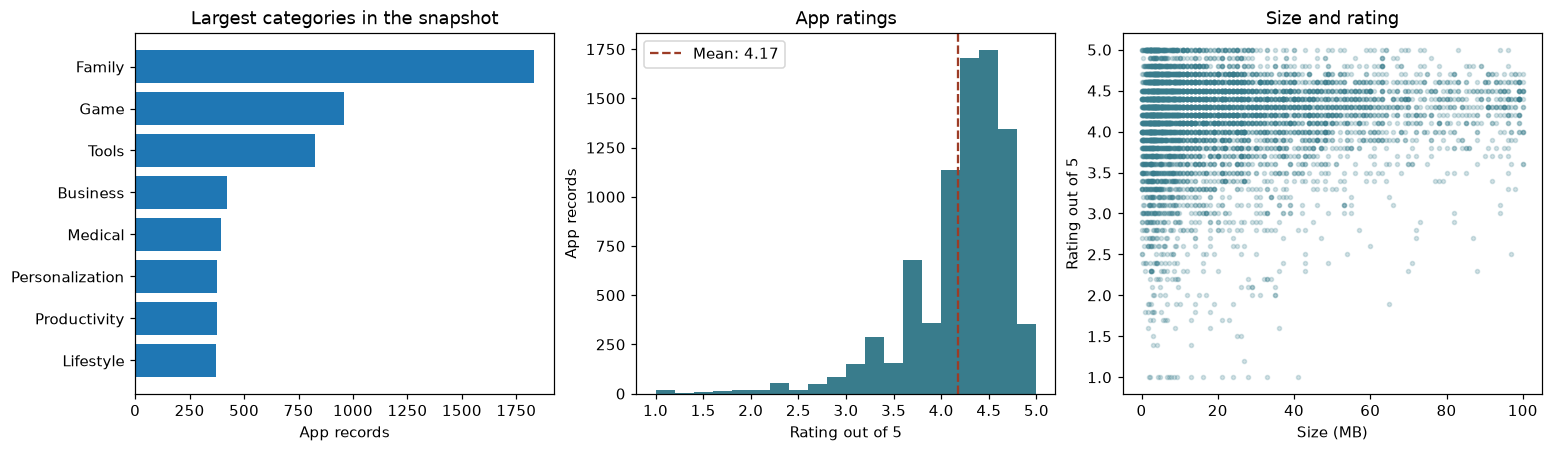

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
category_counts = apps["Category"].value_counts().head(8).sort_values()
axes[0].barh(category_counts.index.str.replace("_", " ").str.title(), category_counts)
axes[0].set(title="Largest categories in the snapshot", xlabel="App records")
axes[1].hist(rated, bins=np.linspace(1, 5, 21), color="#397C8C")
axes[1].axvline(rated.mean(), color="#9C3C26", linestyle="--", label=f"Mean: {rated.mean():.2f}")
axes[1].set(title="App ratings", xlabel="Rating out of 5", ylabel="App records")
axes[1].legend()
sizes = apps.dropna(subset=["Size MB", "Rating"])
axes[2].scatter(sizes["Size MB"], sizes["Rating"], s=7, alpha=0.22, color="#397C8C")
axes[2].set(title="Size and rating", xlabel="Size (MB)", ylabel="Rating out of 5")
plt.show()

## Price and reported installs

A value such as `10,000+` is a lower bound reported by the source. For the price plot, the $100 cutoff limits the display range only. The install plot omits zero thresholds because the axis is logarithmic.

Paid-app prices at $100 or above: 20 of 756 observed prices.
      count    median
Type                 
Free   8903  100000.0
Paid    756    1000.0


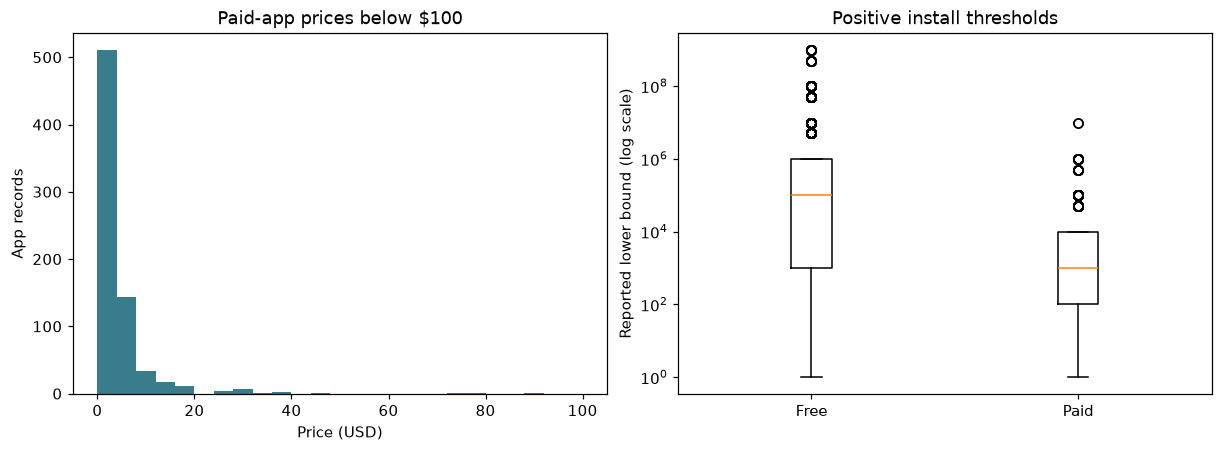

In [3]:
paid_prices = apps.loc[apps["Type"].eq("Paid"), "Price"].dropna()
display_prices = paid_prices[paid_prices.lt(100)]
print(f"Paid-app prices at $100 or above: {(paid_prices >= 100).sum():,} of {len(paid_prices):,} observed prices.")
install_summary = apps.groupby("Type")["Install threshold"].agg(["count", "median"])
print(install_summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].hist(display_prices, bins=np.linspace(0, 100, 26), color="#397C8C")
axes[0].set(title="Paid-app prices below $100", xlabel="Price (USD)", ylabel="App records")
install_groups = [
    apps.loc[apps["Type"].eq(kind) & apps["Install threshold"].gt(0), "Install threshold"].to_numpy()
    for kind in ["Free", "Paid"]
]
axes[1].boxplot(install_groups)
axes[1].set_xticks([1, 2], ["Free", "Paid"])
axes[1].set_yscale("log")
axes[1].set(title="Positive install thresholds", ylabel="Reported lower bound (log scale)")
plt.show()

## Review sentiment by app type

The review file has sentiment scores supplied by the dataset. App name is the only available join key, so names that match multiple app records are excluded. Each app contributes one mean score to the comparison, regardless of how many eligible reviews it has.

Matched 35,934 of 37,432 scored reviews.
Excluded 0 with ambiguous app names and 1,498 with unmatched names.
      count    median
Type                 
Free    807  0.198602
Paid      9  0.181818


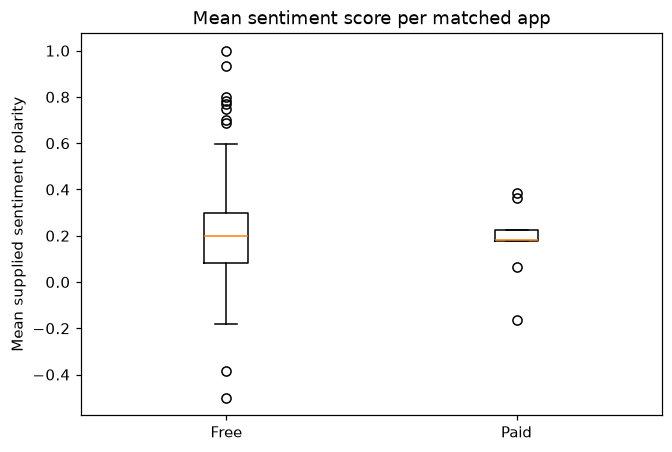

In [4]:
reviews = read_snapshot("user_reviews.csv")
reviews["Sentiment_Polarity"] = pd.to_numeric(reviews["Sentiment_Polarity"], errors="coerce")
scored = reviews.dropna(subset=["App", "Sentiment_Polarity"])

app_names = apps[["App", "Type"]].dropna(subset=["App"])
ambiguous = app_names.loc[app_names["App"].duplicated(keep=False), "App"]
unique_apps = app_names.drop_duplicates("App", keep=False)
matched = scored.merge(unique_apps, on="App", validate="many_to_one")
per_app = matched.groupby(["App", "Type"], as_index=False)["Sentiment_Polarity"].mean()

print(f"Matched {len(matched):,} of {len(scored):,} scored reviews.")
print(f"Excluded {scored['App'].isin(ambiguous).sum():,} with ambiguous app names and "
      f"{(~scored['App'].isin(app_names['App'])).sum():,} with unmatched names.")
print(per_app.groupby("Type")["Sentiment_Polarity"].agg(["count", "median"]).to_string())

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
groups = [per_app.loc[per_app["Type"].eq(kind), "Sentiment_Polarity"] for kind in ["Free", "Paid"]]
ax.boxplot(groups)
ax.set_xticks([1, 2], ["Free", "Paid"])
ax.set(title="Mean sentiment score per matched app", ylabel="Mean supplied sentiment polarity")
plt.show()

## What the data can tell us

The matched sample contains only nine paid apps, and the sentiment scores come from selected reviews. The comparison doesn't tell us whether paid apps are better.

Project source: DataCamp, [The Android App Market on Google Play](https://www.datacamp.com/projects/619).